# Solar Stray-light Background Analysis

## Introduction

Find out what factors dominate the background level as a function of the Solar Pitch angle 
## Imports

In [1]:
import rosalia as rs
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord  # High-level coordinates
from astropy.time import Time
from astroquery.jplhorizons import Horizons
from tqdm import tqdm 
# Initiate the MAST 
import os
from astroquery.mast import MastMissions
from dotenv import load_dotenv

_ = load_dotenv(dotenv_path="./variables.env")

# Create MastMissions object and assign mission to 'roman'
missions = MastMissions(mission='roman')

# Login to search and retrieve Roman data
token = os.getenv("MAST_API_TOKEN")    
missions.login(token=token)
               
print(f'Mission: {missions.mission}')
print(f'Service: {missions.service}')

2026-10-26 12:15:00 INFO     MAST API token accepted, welcome Alejandro Serrano Borlaff


INFO: MAST API token accepted, welcome Alejandro Serrano Borlaff [astroquery.mast.auth]
Mission: roman
Service: search


The purpose of this notebook is to identify the exposures with extreme solar pitch angles 
```

In [2]:
# Read a manually downloaded MAST data table 
from astropy.io.votable import parse_single_table
wfipoint = parse_single_table("/Users/aborlaff/NASA/ROSALIA_DEPOT/Roman_2026-10-23T10_16_52-07_00.xml").to_table()

77111.99957175925
61298.038073854164


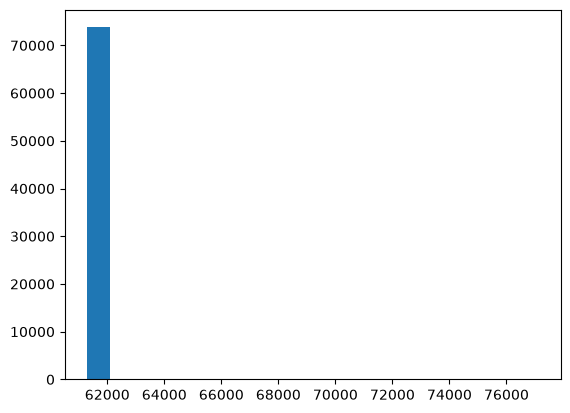

In [4]:
import numpy as np
# Some exposure have the wrong date: 
# Not sure if this is work in progress, but Program 1028 has some observations with wrong visit_start_time in MAST. There is 36 visits with visit_start_time == '2069-12-31T23:59:23'.
mjd = Time(list(wfipoint["visit_start_time"]), format="isot").mjd

wfipoint["mjd"] = mjd

plt.hist(mjd, bins=20)
print(np.max(mjd))
print(np.min(mjd))

# For now we will just clean them
wfipoint = wfipoint[~(wfipoint["visit_start_time"] == '2069-12-31T23:59:23')]
wfipoint["mjd"] = Time(list(wfipoint["visit_start_time"]), format="isot").mjd

In [5]:
# Analyze the location of the Sun, Earth, and Moon from the POV of Roman since launch. 
launch_date = Time('2026-08-31T00:00:00.000', format="isot")
end_date = Time('2026-10-23T00:00:00.000', format="isot")

obj = Horizons(id="10", location="500@-680", epochs={'start':'2026-08-31', 'stop':'2026-10-23', 'step':'1h'})
sun_eph = obj.ephemerides()
obj = Horizons(id="301", location="500@-680", epochs={'start':'2026-08-31', 'stop':'2026-10-23', 'step':'1h'})
moon_eph = obj.ephemerides()
obj = Horizons(id="399", location="500@-680", epochs={'start':'2026-08-31', 'stop':'2026-10-23', 'step':'1h'})
earth_eph = obj.ephemerides()

# Load the bright stars catalog 
gaia_naked_eye_stars = pd.read_csv(os.environ["ROSALIACACHE"] + "/CORE/gaia_naked_eye_stars.csv", sep=" ")

In [6]:
# Plot zone 
plt.style.use('dark_background')
plt.style.use(os.path.dirname(rs.__file__) + "/style/nature_style.mplstyle")

import matplotlib.pyplot as plt
plt.style.use('dark_background')

mjd_list = Time(earth_eph["datetime_jd"], format="jd").mjd


if False:
    for i in tqdm(range(len(earth_eph))):
        
        fig, ax = plt.subplots(figsize=(12,7)) # note we must use plt.subplots, not plt.subplot

        earth_color = "dodgerblue"
        sun_color = "gold"
        moon_color = "silver"
        sun_marker = u'$\u2609$' 
        moon_marker = u'$\u263D$' 
        earth_marker = u'$\u1F728$'
        
        ax.plot(earth_eph["RA"][:i], 
                   earth_eph["DEC"][:i], 
                   color=earth_color, alpha=0.5, linestyle="-", linewidth=2)
        
        ax.plot(sun_eph["RA"][:i], 
                   sun_eph["DEC"][:i], 
                   color=sun_color, alpha=0.5, linestyle="-", linewidth=2)
        
        ax.plot(moon_eph["RA"][:i], 
                   moon_eph["DEC"][:i], 
                   color=moon_color, alpha=0.5, linestyle="-", linewidth=2)
        
        
        earth_circle = plt.Circle((earth_eph["RA"][i], 
                                   earth_eph["DEC"][i]), 
                                   earth_eph["ang_width"][i]/1000, 
                                   color=earth_color)
        ax.add_patch(earth_circle)
        
        sun_circle = plt.Circle((sun_eph["RA"][i], 
                                 sun_eph["DEC"][i]), 
                                 sun_eph["ang_width"][i]/1000, 
                                 color=sun_color)
        ax.add_patch(sun_circle)

        moon_circle = plt.Circle((moon_eph["RA"][i], 
                                  moon_eph["DEC"][i]), 
                                  moon_eph["ang_width"][i]/1000,
                                   color=moon_color)
        ax.add_patch(moon_circle)

        # Add the stars 
        ax.scatter(gaia_naked_eye_stars["ra"], gaia_naked_eye_stars["dec"], 
                   marker="o",     
                   s=35/(gaia_naked_eye_stars["mag_g_ab"]+1), 
                   facecolors='white',  # Inside color
                   edgecolors='white',     # Border color
                   linewidth=1, alpha=0.35)          # Border thickness

        ax.set_xlabel("Right Ascension (degrees)")
        ax.set_ylabel("Declination (degrees)")

        # Add the Roman Pointings 
        past_wfi_pointings = table[table["mjd"] < mjd_list[i]]
        ax.scatter(past_wfi_pointings["ra"], past_wfi_pointings["dec"], 
                   marker="s",     
                   s=35, 
                   facecolors='none',  # Inside color
                   edgecolors='red',     # Border color
                   linewidth=0.1, alpha=0.7, 
                   label="Roman/WFI Commissioning Observations")          # Border thickness

        isot = Time(mjd_list[i], format="mjd").isot
        
        ax.text(280, 80, isot, fontsize=10)
        
        ax.set_xlim(0, 360)
        ax.set_ylim(-90, 90)
        ax.legend(loc="upper left", frameon=False, fontsize=12)
        plt.savefig("earth_moon_sun_from_Roman_" + str(i).zfill(5) + ".png", dpi=100)
        plt.show()

if False:
    import os 
    os.system("magick -delay 2 -loop 0 earth_moon_sun_from_Roman_*.png earth_moon_sun_from_Roman.gif")

In [10]:
from scipy.interpolate import interp1d

mjd_list = Time(sun_eph["datetime_jd"], format="jd").mjd
sun_ra_interpolator = interp1d(x=mjd_list, y=sun_eph["RA"], kind="quadratic", fill_value="extrapolate")
sun_dec_interpolator = interp1d(x=mjd_list, y=sun_eph["DEC"], kind="quadratic", fill_value="extrapolate")

mjd_list = Time(earth_eph["datetime_jd"], format="jd").mjd
earth_ra_interpolator = interp1d(x=mjd_list, y=earth_eph["RA"], kind="quadratic", fill_value="extrapolate")
earth_dec_interpolator = interp1d(x=mjd_list, y=earth_eph["DEC"], kind="quadratic", fill_value="extrapolate")

mjd_list = Time(moon_eph["datetime_jd"], format="jd").mjd
moon_ra_interpolator = interp1d(x=mjd_list, y=moon_eph["RA"], kind="quadratic", fill_value="extrapolate")
moon_dec_interpolator = interp1d(x=mjd_list, y=moon_eph["DEC"], kind="quadratic", fill_value="extrapolate")


# Get the distance to each body from wfi pointing 
wfipoint["sun_ra"] = sun_ra_interpolator(wfipoint["mjd"])
wfipoint["sun_dec"] = sun_dec_interpolator(wfipoint["mjd"])

wfipoint["earth_ra"] = earth_ra_interpolator(wfipoint["mjd"])
wfipoint["earth_dec"] = earth_dec_interpolator(wfipoint["mjd"])

wfipoint["moon_ra"] = moon_ra_interpolator(wfipoint["mjd"])
wfipoint["moon_dec"] = moon_dec_interpolator(wfipoint["mjd"])

wfi_cen = SkyCoord(wfipoint["ra"], wfipoint["dec"], frame="icrs", unit="degree")
sun_skycoord   = SkyCoord(wfipoint["sun_ra"], wfipoint["sun_dec"], frame="icrs", unit="degree")
earth_skycoord = SkyCoord(wfipoint["earth_ra"], wfipoint["earth_dec"], frame="icrs", unit="degree")
moon_skycoord  = SkyCoord(wfipoint["moon_ra"], wfipoint["moon_dec"], frame="icrs", unit="degree")

wfipoint["sun_dist"]    = wfi_cen.separation(sun_skycoord)
wfipoint["earth_dist"]  = wfi_cen.separation(earth_skycoord)
wfipoint["moon_dist"]   = wfi_cen.separation(moon_skycoord)

In [16]:
wfipoint_sunclose = wfipoint[((wfipoint["sun_dist"]-90) < -20)]
wfipoint_sunclose = wfipoint_sunclose[wfipoint_sunclose["calibration_software_version"] == '1.0.2'] 
wfipoint_sunclose

ArchiveFileID,fileSetName,ra,dec,exposure_type,exposure_time,program,visit_start_time,program_subcategory,program_category,calibration_software_version,dataset_category,productLevel,program_title,exposure_start_time,segment,origin,optical_element,detector,search_key,mjd,sun_ra,sun_dec,earth_ra,earth_dec,moon_ra,moon_dec,sun_dist,earth_dist,moon_dist
,,,,,,,,,,,,,,,,,,,,,,,,,,,deg,deg,deg
int64,object,float64,float64,object,float64,int64,object,object,object,object,object,object,object,object,object,object,object,object,object,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
3077513,r0102203053001001001_0001_wfi01_f087,206.9239529652591,49.41410311271571,WFI_IMAGE,66.41188,1022,2026-09-21T04:22:28.7490000,WFI,COM,1.0.2,detector,"1, 2, 4",WFI_IMAGING,2026-09-21T04:23:08.5330000,1,STSCI/SOC,F087,WFI01,3077513,61304.1822771875,177.92821509330054,1.009149786738548,165.82798106367244,19.040290506207832,181.60162242289078,13.989945492689063,54.385632558657925,44.666026427098906,41.042163025637244
3077519,r0102203053001001001_0001_wfi02_f087,206.7853364305638,49.52916378057071,WFI_IMAGE,66.41188,1022,2026-09-21T04:22:28.7490000,WFI,COM,1.0.2,detector,"1, 2, 4",WFI_IMAGING,2026-09-21T04:23:08.5330000,1,STSCI/SOC,F087,WFI02,3077519,61304.1822771875,177.92821509330054,1.009149786738548,165.82798106367244,19.040290506207832,181.60162242289078,13.989945492689063,54.42456037147512,44.640533216990804,41.07472532860786
3077492,r0102203053001001001_0001_wfi03_f087,206.6608386671207,49.63191197960867,WFI_IMAGE,66.41188,1022,2026-09-21T04:22:28.7490000,WFI,COM,1.0.2,detector,"1, 2, 4",WFI_IMAGING,2026-09-21T04:23:08.5330000,1,STSCI/SOC,F087,WFI03,3077492,61304.1822771875,177.92821509330054,1.009149786738548,165.82798106367244,19.040290506207832,181.60162242289078,13.989945492689063,54.459583221633366,44.61805175734501,41.10419053229939
3077504,r0102203053001001001_0001_wfi04_f087,207.1135835505218,49.47622728353947,WFI_IMAGE,66.41188,1022,2026-09-21T04:22:28.7490000,WFI,COM,1.0.2,detector,"1, 2, 4",WFI_IMAGING,2026-09-21T04:23:08.5330000,1,STSCI/SOC,F087,WFI04,3077504,61304.1822771875,177.92821509330054,1.009149786738548,165.82798106367244,19.040290506207832,181.60162242289078,13.989945492689063,54.509115630100546,44.8040625947826,41.16833541254273
3077498,r0102203053001001001_0001_wfi05_f087,206.9751483784528,49.59178179530177,WFI_IMAGE,66.41188,1022,2026-09-21T04:22:28.7490000,WFI,COM,1.0.2,detector,"1, 2, 4",WFI_IMAGING,2026-09-21T04:23:08.5330000,1,STSCI/SOC,F087,WFI05,3077498,61304.1822771875,177.92821509330054,1.009149786738548,165.82798106367244,19.040290506207832,181.60162242289078,13.989945492689063,54.548115078933456,44.778636830089916,41.200908426865254
3077435,r0102203053001001001_0001_wfi06_f087,206.8512803019806,49.69437312832331,WFI_IMAGE,66.41188,1022,2026-09-21T04:22:28.7490000,WFI,COM,1.0.2,detector,"1, 2, 4",WFI_IMAGING,2026-09-21T04:23:08.5330000,1,STSCI/SOC,F087,WFI06,3077435,61304.1822771875,177.92821509330054,1.009149786738548,165.82798106367244,19.040290506207832,181.60162242289078,13.989945492689063,54.58290022364578,44.75620034479573,41.23010793156613
3077441,r0102203053001001001_0001_wfi07_f087,207.3397265404465,49.50718682956474,WFI_IMAGE,66.41188,1022,2026-09-21T04:22:28.7490000,WFI,COM,1.0.2,detector,"1, 2, 4",WFI_IMAGING,2026-09-21T04:23:08.5330000,1,STSCI/SOC,F087,WFI07,3077441,61304.1822771875,177.92821509330054,1.009149786738548,165.82798106367244,19.040290506207832,181.60162242289078,13.989945492689063,54.622081929343985,44.948561697314716,41.28574230346966
3077417,r0102203053001001001_0001_wfi08_f087,207.2016483123306,49.62354882646923,WFI_IMAGE,66.41188,1022,2026-09-21T04:22:28.7490000,WFI,COM,1.0.2,detector,"1, 2, 4",WFI_IMAGING,2026-09-21T04:23:08.5330000,1,STSCI/SOC,F087,WFI08,3077417,61304.1822771875,177.92821509330054,1.009149786738548,165.82798106367244,19.040290506207832,181.60162242289078,13.989945492689063,54.66130325783709,44.92323099188873,41.3184270501139


In [ ]:
products =  missions.get_product_list(wfipoint_sunclose)

Fetching products for 15655 unique datasets in 16 batches ... [Done]


product_key,access,dataset,instrument_name,filters,filename,uri,authz_primary_identifier,authz_secondary_identifier,file_suffix,suffix_description,category,size,type,obs_collection,project,mrp,calibration_software_version,crds_context_used,crds_software_version,edp_url
str85,str6,str36,str3,str4,str48,str85,str48,str48,str8,str1,str11,int64,str18,str1,str1,bool,str5,str15,str6,str92
r0102206131001002001_0001_wfi13_f158_r0102206131001002001_0001_wfi13_f158_segm.asdf,PUBLIC,r0102206131001002001_0001_wfi13_f158,WFI,,r0102206131001002001_0001_wfi13_f158_segm.asdf,r0102206131001002001_0001_wfi13_f158/r0102206131001002001_0001_wfi13_f158_segm.asdf,r0102206131001002001_0001_wfi13_f158_segm.asdf,r0102206131001002001_0001_wfi13_f158_segm.asdf,_segm,,4,67511213,level_four_product,,,False,,,,/edp/#/roman?start_date=2026-10-05&start_time=04:40:40&end_date=2026-10-05&end_time=04:42:30
r0102206131001002001_0001_wfi13_f158_r0102206131001002001_0001_wfi13_f158_cat.parquet,PUBLIC,r0102206131001002001_0001_wfi13_f158,WFI,,r0102206131001002001_0001_wfi13_f158_cat.parquet,r0102206131001002001_0001_wfi13_f158/r0102206131001002001_0001_wfi13_f158_cat.parquet,r0102206131001002001_0001_wfi13_f158_cat.parquet,r0102206131001002001_0001_wfi13_f158_cat.parquet,_cat,,4,470591,level_four_product,,,False,,,,/edp/#/roman?start_date=2026-10-05&start_time=04:40:40&end_date=2026-10-05&end_time=04:42:30
r0102206131001002001_0001_wfi13_f158_r0102206131001002001_0001_wfi13_f158_uncal.asdf,PUBLIC,r0102206131001002001_0001_wfi13_f158,WFI,F158,r0102206131001002001_0001_wfi13_f158_uncal.asdf,r0102206131001002001_0001_wfi13_f158/r0102206131001002001_0001_wfi13_f158_uncal.asdf,r0102206131001002001_0001_wfi13_f158_uncal.asdf,r0102206131001002001_0001_wfi13_f158_uncal.asdf,_uncal,,1,214983678,science,,,False,1.0.2,,,/edp/#/roman?start_date=2026-10-05&start_time=04:40:40&end_date=2026-10-05&end_time=04:42:30
r0102206131001002001_0001_wfi13_f158_r0102206131001002001_0001_wfi13_f158_cal.asdf,PUBLIC,r0102206131001002001_0001_wfi13_f158,WFI,F158,r0102206131001002001_0001_wfi13_f158_cal.asdf,r0102206131001002001_0001_wfi13_f158/r0102206131001002001_0001_wfi13_f158_cal.asdf,r0102206131001002001_0001_wfi13_f158_cal.asdf,r0102206131001002001_0001_wfi13_f158_cal.asdf,_cal,,2,209621299,science,,,False,1.0.2,roman_0073.pmap,14.0.0,/edp/#/roman?start_date=2026-10-05&start_time=04:40:40&end_date=2026-10-05&end_time=04:42:30
r0102206131001002001_0001_wfi13_f158_r0102206131001002001_0001_wfi13_f158_wcs.asdf,PUBLIC,r0102206131001002001_0001_wfi13_f158,WFI,F158,r0102206131001002001_0001_wfi13_f158_wcs.asdf,r0102206131001002001_0001_wfi13_f158/r0102206131001002001_0001_wfi13_f158_wcs.asdf,r0102206131001002001_0001_wfi13_f158_wcs.asdf,r0102206131001002001_0001_wfi13_f158_wcs.asdf,_wcs,,2,49225,science,,,False,1.0.2,,,/edp/#/roman?start_date=2026-10-05&start_time=04:40:40&end_date=2026-10-05&end_time=04:42:30
r0102206131001002001_0001_wfi13_f158_r0102206131001002001_0001_wfi13_f158_preview.png,PUBLIC,r0102206131001002001_0001_wfi13_f158,WFI,F158,r0102206131001002001_0001_wfi13_f158_preview.png,r0102206131001002001_0001_wfi13_f158/r0102206131001002001_0001_wfi13_f158_preview.png,r0102206131001002001_0001_wfi13_f158_preview.png,r0102206131001002001_0001_wfi13_f158_preview.png,_preview,,2,2157711,science,,,False,1.0.2,,,/edp/#/roman?start_date=2026-10-05&start_time=04:40:40&end_date=2026-10-05&end_time=04:42:30
r0102206131001002001_0001_wfi13_f158_r0102206131001002001_0001_wfi13_f158_thumb.png,PUBLIC,r0102206131001002001_0001_wfi13_f158,WFI,F158,r0102206131001002001_0001_wfi13_f158_thumb.png,r0102206131001002001_0001_wfi13_f158/r0102206131001002001_0001_wfi13_f158_thumb.png,r0102206131001002001_0001_wfi13_f158_thumb.png,r0102206131001002001_0001_wfi13_f158_thumb.png,_thumb,,2,107328,science,,,False,1.0.2,,,/edp/#/roman?start_date=2026-10-05&start_time=04:40:40&end_date=2026-10-05&end_time=04:42:30
r0102206131001002001_0001_wfi13_f158_r0102206131001002001_1_wfi13_f158_gw.asdf,PUBLIC,r010220613100

In [21]:
products = missions.filter_products(products, file_suffix='_cal')

In [ ]:
from astropy.table import Table
# Write to VOTable format
products.write("roman_wfi_sunclose_clean_exposures_23Oct2026.xml", format="votable", overwrite=True)

In [12]:
# Read a manually downloaded MAST data table 
from astropy.io.votable import parse_single_table
products = parse_single_table("roman_wfi_sunclose_clean_exposures_23Oct2026.xml").to_table()

In [14]:
products

product_key,access,dataset,instrument_name,filters,filename,uri,authz_primary_identifier,authz_secondary_identifier,file_suffix,suffix_description,category,size,type,obs_collection,project,mrp,calibration_software_version,crds_context_used,crds_software_version,edp_url
str85,str6,str36,str3,str4,str48,str85,str48,str48,str8,str1,str11,int64,str18,str1,str1,bool,str5,str15,str6,str92
r0102206131001002001_0001_wfi13_f158_r0102206131001002001_0001_wfi13_f158_cal.asdf,PUBLIC,r0102206131001002001_0001_wfi13_f158,WFI,F158,r0102206131001002001_0001_wfi13_f158_cal.asdf,r0102206131001002001_0001_wfi13_f158/r0102206131001002001_0001_wfi13_f158_cal.asdf,r0102206131001002001_0001_wfi13_f158_cal.asdf,r0102206131001002001_0001_wfi13_f158_cal.asdf,_cal,,2,209621299,science,,,False,1.0.2,roman_0073.pmap,14.0.0,/edp/#/roman?start_date=2026-10-05&start_time=04:40:40&end_date=2026-10-05&end_time=04:42:30
r0105404005001001010_0003_wfi15_f106_r0105404005001001010_0003_wfi15_f106_cal.asdf,PUBLIC,r0105404005001001010_0003_wfi15_f106,WFI,F106,r0105404005001001010_0003_wfi15_f106_cal.asdf,r0105404005001001010_0003_wfi15_f106/r0105404005001001010_0003_wfi15_f106_cal.asdf,r0105404005001001010_0003_wfi15_f106_cal.asdf,r0105404005001001010_0003_wfi15_f106_cal.asdf,_cal,,2,207481183,science,,,False,1.0.2,roman_0076.pmap,13.2.9,/edp/#/roman?start_date=2026-10-12&start_time=01:21:21&end_date=2026-10-12&end_time=01:22:24
r0105404005001001014_0003_wfi01_f106_r0105404005001001014_0003_wfi01_f106_cal.asdf,PUBLIC,r0105404005001001014_0003_wfi01_f106,WFI,F106,r0105404005001001014_0003_wfi01_f106_cal.asdf,r0105404005001001014_0003_wfi01_f106/r0105404005001001014_0003_wfi01_f106_cal.asdf,r0105404005001001014_0003_wfi01_f106_cal.asdf,r0105404005001001014_0003_wfi01_f106_cal.asdf,_cal,,2,209485584,science,,,False,1.0.2,roman_0076.pmap,13.2.9,/edp/#/roman?start_date=2026-10-12&start_time=01:42:34&end_date=2026-10-12&end_time=01:43:37
r0105404005001001022_0002_wfi06_f106_r0105404005001001022_0002_wfi06_f106_cal.asdf,PUBLIC,r0105404005001001022_0002_wfi06_f106,WFI,F106,r0105404005001001022_0002_wfi06_f106_cal.asdf,r0105404005001001022_0002_wfi06_f106/r0105404005001001022_0002_wfi06_f106_cal.asdf,r0105404005001001022_0002_wfi06_f106_cal.asdf,r0105404005001001022_0002_wfi06_f106_cal.asdf,_cal,,2,207998344,science,,,False,1.0.2,roman_0076.pmap,13.2.9,/edp/#/roman?start_date=2026-10-12&start_time=02:23:06&end_date=2026-10-12&end_time=02:24:09
r0105404006001001019_0001_wfi13_f129_r0105404006001001019_0001_wfi13_f129_cal.asdf,PUBLIC,r0105404006001001019_0001_wfi13_f129,WFI,F129,r0105404006001001019_0001_wfi13_f129_cal.asdf,r0105404006001001019_0001_wfi13_f129/r0105404006001001019_0001_wfi13_f129_cal.asdf,r0105404006001001019_0001_wfi13_f129_cal.asdf,r0105404006001001019_0001_wfi13_f129_cal.asdf,_cal,,2,208671153,science,,,False,1.0.2,roman_0076.pmap,13.2.9,/edp/#/roman?start_date=2026-10-12&start_time=04:58:26&end_date=2026-10-12&end_time=04:59:29
r0105405011001001016_0001_wfi03_f213_r0105405011001001016_0001_wfi03_f213_cal.asdf,PUBLIC,r0105405011001001016_0001_wfi03_f213,WFI,F213,r0105405011001001016_0001_wfi03_f213_cal.asdf,r0105405011001001016_0001_wfi03_f213/r0105405011001001016_0001_wfi03_f213_cal.asdf,r0105405011001001016_0001_wfi03_f213_cal.asdf,r0105405011001001016_0001_wfi03_f213_cal.asdf,_cal,,2,208373108,science,,,False,1.0.2,roman_0077.pmap,13.2.9,/edp/#/roman?start_date=2026-10-19&start_time=22:39:33&end_date=2026-10-19&end_time=22:40:36
r0105405011001001018_0001_wfi05_f213_r0105405011001001018_0001_wfi05_f213_cal.asdf,PUBLIC,r0105405011001001018_0001_wfi05_f213,WFI,F213,r0105405011001001018_0001_wfi05_f213_cal.asdf,r0105405011001001018_0001_wfi05_f213/r0105405011001001018_0001_wfi05_f213_cal.asdf,r0105405011001001018_0001_wfi05_f213_cal.asdf,r0105405011001001018_0001_wfi05_f213_cal.asdf,_cal,,2,208786769,science,,,False,1.0.2,roman_0077.pmap,13.2.9,/edp/#/roman?start_date=2026-10-19&start_time=22:43:40&end_date=2026-10-19&end_time=22:44:43
r0105405011001002018_00

In [4]:
products, unique_roots = rs.mast.query.pack_exposures(products)

In [10]:
len(unique_roots)
products["exposure_id"]

r0102206131001002001_0001
r0105404005001001010_0003
r0105404005001001014_0003
r0105404005001001022_0002
r0105404006001001019_0001
r0105405011001001016_0001
r0105405011001001018_0001
r0105405011001002018_0001
r0105501001001004001_0005
r0105501001001005006_0006
r0105501001001007009_0005


In [11]:
unique_roots[0]

'r0105405011001003007_0001'

In [7]:
downloaded_files = rs.mast.query.download_results(products=products, exposures=unique_roots[0])

F129
F106
F213
F184
F158
F087
F146
F062


  0%|          | 0/25 [00:00<?, ?it/s]


IndexError: index 0 is out of bounds for axis 0 with size 0

In [ ]:



fig, ax = plt.subplots(figsize=(12,8))
ax.scatter(table["ra"], table["dec"], c=table["mjd"],  alpha=0.2)
plt.show()

# Find the distance and position angle to the Sun for each visit. 

# Aprox location of the Sun and planets from Roman POV for test. 
from tqdm import tqdm
ra_sun = np.zeros(len(table))
dec_sun = np.zeros(len(table))
#     SSO_list = ["10", "301", "399", "199", "299", "499", "599", "699", "799", "899", "999"]
#     SSO_list_plain = ["Sun", "Moon", "Earth", "Mercury", "Venus", "Mars", "Jupiter", "Saturn", "Uranus", "Neptune", "Pluto"]
#     Roman ID in JPL/Horizons "500@-680"
obj = Horizons(id="10", location="500@-680", epochs=Time(list(table["visit_start_time"]), format="isot").jd[0])
sun_eph = obj.ephemerides()
obj = Horizons(id="399", location="500@-680", epochs=Time(list(table["visit_start_time"]), format="isot").jd[0])
earth_eph = obj.ephemerides()

# sun = SkyCoord(ra_sun*u.degree, dec_sun*u.degree, frame="icrs")
# pointing = SkyCoord(np.array(table["ra"])*u.degree, np.array(table["dec"])*u.degree, frame="icrs")


# d_sun = sun.separation(pointing).degree
    # d_MW[i] = rs.utils.distance_to_galactic_plane(ra_target, dec_target)

#CAR170_db["d_sun"] = d_sun
# CAR170_db["d_MW"] = d_MW


## About this Notebook

**Author:** Alejandro S. Borlaff - NASA Ames Research Center (Code S) - a.s.borlaff@nasa.gov 

**Updated on** September 20, 2026. 

exposure_products